# Fine-tuning - detect Spam messages


### Load the SMS Spam dataset


In [1]:
from datasets import load_dataset

sms_spam_dataset = load_dataset("ucirvine/sms_spam")
print(sms_spam_dataset)

DatasetDict({
    train: Dataset({
        features: ['sms', 'label'],
        num_rows: 5574
    })
})


In [2]:
sms_spam_dataset["train"][0]

{'sms': 'Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...\n',
 'label': 0}

### Train-Test Split


In [3]:
train_test_split = 0.9

shuffled_dataset = sms_spam_dataset["train"].shuffle()
train_len = int(len(shuffled_dataset) * train_test_split)

training_data = shuffled_dataset[:train_len]
validation_data = shuffled_dataset[train_len:]

In [4]:
def get_spam_non_spam_count(data):
    spam = 0
    for label in data["label"]:
        if label == 1:
            spam += 1
    print(f"Spam: {spam}, Non Spam: {len(data['label']) - spam}")
    print(f"Spam: {(spam/len(data['label']))*100}%")


print(f"Training data size: {len(training_data['sms'])}")
get_spam_non_spam_count(training_data)
print(f"Validation data size: {len(validation_data['sms'])}")
get_spam_non_spam_count(validation_data)

Training data size: 5016
Spam: 687, Non Spam: 4329
Spam: 13.696172248803828%
Validation data size: 558
Spam: 60, Non Spam: 498
Spam: 10.75268817204301%


## Tokenize the dataset


In [5]:
from transformers import GPT2Tokenizer

tokenizer = GPT2Tokenizer.from_pretrained("gpt2")

In [6]:
def tokenize_dataset(dataset):
    tokenized_dataset = []

    for message, label in zip(dataset["sms"], dataset["label"]):
        encoded_ids = tokenizer.encode(message)
        tokenized_dataset.append((encoded_ids, label))

    return tokenized_dataset

In [7]:
tokenized_training_dataset = tokenize_dataset(training_data)
tokenized_validation_dataset = tokenize_dataset(validation_data)

print(tokenized_training_dataset[0])
print(tokenizer.decode(tokenized_training_dataset[0][0]))

([3666, 2156, 994, 304, 6766, 2407, 3223, 300, 13481, 986, 1002, 43079, 788, 1392, 12226, 407, 362, 1057, 1541, 46048, 986, 679, 68, 986, 198], 0)
My house here e sky quite dark liao... If raining then got excuse not 2 run already rite... Hee...



## Load GPT-2 Model


In [ ]:
import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DEVICE

'cpu'

In [51]:
from transformers import GPT2Model

model = GPT2Model.from_pretrained("gpt2")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [52]:
model

GPT2Model(
  (wte): Embedding(50257, 768)
  (wpe): Embedding(1024, 768)
  (drop): Dropout(p=0.1, inplace=False)
  (h): ModuleList(
    (0-11): 12 x GPT2Block(
      (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
      (attn): GPT2Attention(
        (c_attn): Conv1D(nf=2304, nx=768)
        (c_proj): Conv1D(nf=768, nx=768)
        (attn_dropout): Dropout(p=0.1, inplace=False)
        (resid_dropout): Dropout(p=0.1, inplace=False)
      )
      (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
      (mlp): GPT2MLP(
        (c_fc): Conv1D(nf=3072, nx=768)
        (c_proj): Conv1D(nf=768, nx=3072)
        (act): NewGELUActivation()
        (dropout): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
)

We can see the final (Layer-Norm) layer has an out dimension of **768**. We need to add an additional custom layer after the LayerNorm layer which will classify the input text as **spam (0)** or **not-spam (1)**.

Before that let's generate some content from the GPT-2 model.


In [53]:
from transformers import pipeline

generator = pipeline("text-generation", model="gpt2")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [54]:
generator("kill him", max_length=30, num_return_sequences=1)

[transformers] Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[{'generated_text': 'kill him and his wife, and take him to heaven, and we shall see that he is not in danger.\n\n14 And Jesus said to the Pharisees, "What did you do to me?" And they said, "He asked you to take him to heaven, and I said, \'I will take him to heaven.\'"\n\n15 And Jesus answered, "If you do not go out to the people to kill them, you shall be judged by the law, and not by the Spirit of God."\n\n16 So the Pharisees went and took him to heaven, and Judas and his wife and his two daughters, and put him in the temple. But Jesus said to them, "If anyone will take thee to heaven, let him take you to the Father."\n\n17 And he was taken to heaven, and he was taken up, and he was taken down, and he was taken to the Father, and he was taken up to the Father, and he was taken up to the Father, and he was taken up to the Father, and he was taken up to the Father, and he was taken up to the Father, and he was taken up to the Father, and he was taken up to the Father, and he was'}]

In [ ]:
from torch import nn
import torch


class GptSpamClass(nn.Module):
    def __init__(self):
        super(GptSpamClass, self).__init__()

        self.gpt2 = GPT2Model.from_pretrained("gpt2")  # out dimension = 768
        self.out_layer = nn.Linear(768, 2)  # out dimension = 2

    def forward(self, input_ids):
        outputs = self.gpt2.forward(input_ids=input_ids)
        hidden_states = outputs.last_hidden_state

        # Because GPT-2 is a causal (left-to-right) model, the meaningful context
        # for the whole sentence accumulates at the VERY LAST token.
        # So, we usually extract just the last token's hidden state to pass to our new layer.

        # Grab the last token's representation for each sequence in the batch
        # (Assuming you are padding appropriately)
        last_token_states = hidden_states[:, -1, :]  # B, 1, 768

        final_output = self.out_layer(last_token_states)  # B, 1, 2

        return final_output

    def predict(self, sms: str):
        self.eval()
        device = next(self.parameters()).device

        with torch.no_grad():
            encoded_ids = tokenizer.encode(sms)
            encoded_ids = torch.tensor([encoded_ids], device=device)

            logits = self.forward(encoded_ids)
            predicted_label = torch.argmax(logits, dim=-1)


        return "Not Spam" if predicted_label == 0 else "Spam"

In [56]:
gpt2_spam_model = GptSpamClass().to(DEVICE)
gpt2_spam_model

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GptSpamClass(
  (gpt2): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (out_layer): Linear(in_features=768, out_features=2, bias=True)
)

In [57]:
f"{(sum(parameter.numel() for parameter in gpt2_spam_model.parameters()) / 1e6):.2f} million parameters"

'124.44 million parameters'

### Fine-tune


In [58]:
# Feeze the entire model
for parameter in gpt2_spam_model.parameters():
    parameter.requires_grad = False

# Making the last attention block trainable
for parameter in gpt2_spam_model.gpt2.h[-1].parameters():
    parameter.requires_grad = True

# Making the last output layer trainable as well
for parameter in gpt2_spam_model.out_layer.parameters():
    parameter.requires_grad = True

In [59]:
sum(parameter.numel() for parameter in gpt2_spam_model.out_layer.parameters()) + sum(
    parameter.numel() for parameter in gpt2_spam_model.gpt2.h[-1].parameters()
)

7089410

In [60]:
def get_mean(losses):
    sum = 0.0
    for loss in losses:
        sum += loss.item()
    return sum / len(losses)

In [61]:
from torch.nn.utils.rnn import pad_sequence

gpt2_spam_model.train()

epochs = 2
batch_size = 8
eval_intervals = batch_size * 50
losses = []
overall_losses = []

optimizer = torch.optim.AdamW(gpt2_spam_model.parameters(), lr=5e-5, weight_decay=0.1)

for epoch in range(epochs):
    Xb = []
    Yb = []
    print(f"Epoch: {epoch+1}")

    for i, row in enumerate(tokenized_training_dataset):
        encoded_msg = row[0]
        label = row[1]
        Xb.append(torch.tensor(encoded_msg))
        Yb.append(torch.tensor(label))

        if (len(Xb) % batch_size) == 0:
            optimizer.zero_grad()

            padded_batch = pad_sequence(Xb, batch_first=True, padding_value=0).to(
                DEVICE
            )
            labels = torch.stack(Yb).to(DEVICE)
            logits = gpt2_spam_model(padded_batch)
            loss = torch.nn.functional.cross_entropy(logits, labels)

            losses.append(loss)
            overall_losses.append(loss)

            loss.backward()
            optimizer.step()
            Xb = []
            Yb = []

            if (i + 1) % eval_intervals == 0:
                print(f"Interval: {i+1}, Loss: {get_mean(losses)}")
                losses = []

    if len(Xb) > 0:
        optimizer.zero_grad()

        padded_batch = pad_sequence(Xb, batch_first=True, padding_value=0).to(DEVICE)
        labels = torch.stack(Yb).to(DEVICE)
        logits = gpt2_spam_model(padded_batch)
        loss = torch.nn.functional.cross_entropy(logits, labels)

        losses.append(loss)
        overall_losses.append(loss)
        
        loss.backward()
        optimizer.step()

Epoch: 1
Interval: 400, Loss: 0.45795132525265214
Interval: 800, Loss: 0.3795238574594259
Interval: 1200, Loss: 0.26596999518573283
Interval: 1600, Loss: 0.2905381299555302
Interval: 2000, Loss: 0.23626129887998104
Interval: 2400, Loss: 0.23906960368156432
Interval: 2800, Loss: 0.17174692925065757
Interval: 3200, Loss: 0.16681408135220407
Interval: 3600, Loss: 0.1740190645866096
Interval: 4000, Loss: 0.137586403246969
Interval: 4400, Loss: 0.1486902812682092
Interval: 4800, Loss: 0.12564637524075806
Epoch: 2
Interval: 400, Loss: 0.09635261207359372
Interval: 800, Loss: 0.12120778684969992
Interval: 1200, Loss: 0.09930566805647686
Interval: 1600, Loss: 0.08727714322973043
Interval: 2000, Loss: 0.07263653841335327
Interval: 2400, Loss: 0.0713601650018245
Interval: 2800, Loss: 0.11169085213681683
Interval: 3200, Loss: 0.09672421685885638
Interval: 3600, Loss: 0.1119576756830793
Interval: 4000, Loss: 0.07800881623523309
Interval: 4400, Loss: 0.09606923441402614
Interval: 4800, Loss: 0.0758

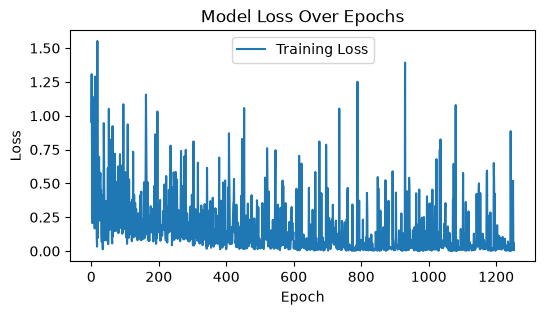

In [62]:
import matplotlib.pyplot as plt


def plot_loss_curve(losses):
    loss_list = [loss.item() for loss in losses]

    # Plot the loss curve
    plt.figure(figsize=(6, 3))  # Optional: adjust figure size
    plt.plot(loss_list, label="Training Loss")

    # Add titles and labels
    plt.title("Model Loss Over Epochs")
    plt.ylabel("Loss")
    plt.xlabel("Epoch")
    plt.legend()  # Show the legend

    # Display the plot
    plt.show()


plot_loss_curve(overall_losses)

In [63]:
def get_dataset_accuracy(model, tokenized_dataset, log_interval):

    model.eval()
    device = next(model.parameters()).device

    encoded_messages = [row[0] for row in tokenized_dataset]
    labels = [row[1] for row in tokenized_dataset]
    processed = 0
    correct_predictions = 0

    for encoded_message, label in zip(encoded_messages, labels):
        with torch.no_grad():
            encoded_message = torch.tensor(encoded_message).view(
                1, len(encoded_message)
            )
            logits = model(torch.tensor(encoded_message).to(device))
        predicted_label = torch.argmax(logits, dim=-1)

        if predicted_label == label:
            correct_predictions += 1

        if processed % log_interval == 0:
            print(f"Processed: {processed}")
        processed += 1

    print(f"{correct_predictions} / {len(encoded_messages)}")
    accuracy = (correct_predictions / len(encoded_messages)) * 100.0
    print(f"Accuracy: {accuracy}")

    return accuracy

In [64]:
train_accuracy = get_dataset_accuracy(
    gpt2_spam_model, tokenized_training_dataset, log_interval=500
)
print(f"Training dataset accuracy: {train_accuracy}")

C:\Users\USER\AppData\Local\Temp\ipykernel_32084\283834730.py:16: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  logits = model(torch.tensor(encoded_message).to(device))


Processed: 0
Processed: 500
Processed: 1000
Processed: 1500
Processed: 2000
Processed: 2500
Processed: 3000
Processed: 3500
Processed: 4000
Processed: 4500
Processed: 5000
4913 / 5016
Accuracy: 97.94657097288676
Training dataset accuracy: 97.94657097288676


In [65]:
validation_accuracy = get_dataset_accuracy(
    gpt2_spam_model, tokenized_validation_dataset, log_interval=100
)
print(f"Validation dataset accuracy: {validation_accuracy}")

Processed: 0


C:\Users\USER\AppData\Local\Temp\ipykernel_32084\283834730.py:16: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  logits = model(torch.tensor(encoded_message).to(device))


Processed: 100
Processed: 200
Processed: 300
Processed: 400
Processed: 500
551 / 558
Accuracy: 98.74551971326166
Validation dataset accuracy: 98.74551971326166


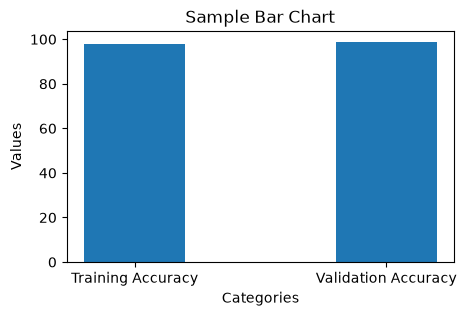

In [66]:
import numpy as np


def plot_bar_chart(training_accuracy, validation_accuracy):
    # Data for the bar chart
    categories = np.array(["Training Accuracy", "Validation Accuracy"])
    values = np.array([training_accuracy, validation_accuracy])

    # Create the bar chart
    plt.figure(figsize=(5, 3))
    plt.bar(categories, values, width=0.4)

    # Add labels and a title
    plt.xlabel("Categories")
    plt.ylabel("Values")
    plt.title("Sample Bar Chart")

    # Display the chart
    plt.show()


plot_bar_chart(train_accuracy, validation_accuracy)

In [67]:
messages = [
    "Last a chance to win 1 Lakh, call at 5676 now!",
    "How are you doing?",
    "Get home loan at low rates now, click to this link http://win/ to know more",
    "Reaching your location in 5 minutes",
]

for message in messages:
    prediction = gpt2_spam_model.predict(message)
    print(f"{message} -> {prediction}")

Last a chance to win 1 Lakh, call at 5676 now! -> Not Spam
How are you doing? -> Not Spam
Get home loan at low rates now, click to this link http://win/ to know more -> Spam
Reaching your location in 5 minutes -> Not Spam


## Using BERT


In [ ]:
import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DEVICE

In [39]:
from transformers import BertTokenizer

# Replace GPT2Tokenizer with BertTokenizer
tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

# Your tokenize_dataset function remains exactly the same!
tokenized_training_dataset = tokenize_dataset(training_data)
tokenized_validation_dataset = tokenize_dataset(validation_data)

In [40]:
from transformers import BertModel
from torch import nn
import torch


class BertSpamClass(nn.Module):
    def __init__(self):
        super(BertSpamClass, self).__init__()

        # Load BERT instead of GPT-2
        self.bert = BertModel.from_pretrained(
            "bert-base-uncased"
        )  # out dimension = 768
        self.out_layer = nn.Linear(768, 2)  # out dimension = 2

    def forward(self, input_ids):
        # Dynamically create attention mask (1 for real tokens, 0 for padding)
        # This allows your existing training loop using pad_sequence to work perfectly.
        attention_mask = (input_ids != 0).long()

        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        hidden_states = outputs.last_hidden_state

        # CRITICAL CHANGE: BERT uses the [CLS] token (the very first token at index 0)
        # to represent the context of the whole sequence, not the last token.
        cls_token_states = hidden_states[:, 0, :]  # B, 768

        final_output = self.out_layer(cls_token_states)  # B, 2

        return final_output

    def predict(self, sms: str):
        self.eval() 
        device = next(self.parameters()).device

        encoded_ids = tokenizer.encode(sms)
        encoded_ids = torch.tensor([encoded_ids], device=device)

        logits = self.forward(encoded_ids)
        predicted_label = torch.argmax(logits, dim=-1)

        verdict = "Not Spam" if predicted_label == 0 else "Spam"

        return verdict

In [41]:
bert_spam_ham_model = BertSpamClass().to(DEVICE)
bert_spam_ham_model

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BertSpamClass(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12, elem

In [42]:
f"{(sum(parameter.numel() for parameter in bert_spam_ham_model.parameters()) / 1e6):.2f} million parameters"

'109.48 million parameters'

### Fine Tune BERT


In [43]:
# Freeze the entire model
for parameter in bert_spam_ham_model.parameters():
    parameter.requires_grad = False

# CRITICAL CHANGE: Accessing the last attention block in BERT
for parameter in bert_spam_ham_model.bert.encoder.layer[-1].parameters():
    parameter.requires_grad = True

# Making the last output layer trainable as well
for parameter in bert_spam_ham_model.out_layer.parameters():
    parameter.requires_grad = True

In [44]:
from torch.nn.utils.rnn import pad_sequence

bert_spam_ham_model.train()

epochs = 2
batch_size = 8
eval_intervals = batch_size * 50
losses = []
overall_losses = []

optimizer = torch.optim.AdamW(
    bert_spam_ham_model.parameters(), lr=5e-5, weight_decay=0.1
)

for epoch in range(epochs):
    Xb = []
    Yb = []
    print(f"Epoch: {epoch+1}")

    for i, row in enumerate(tokenized_training_dataset):
        encoded_msg = row[0]
        label = row[1]
        Xb.append(torch.tensor(encoded_msg))
        Yb.append(torch.tensor(label))

        if (len(Xb) % batch_size) == 0:
            optimizer.zero_grad()

            padded_batch = pad_sequence(Xb, batch_first=True, padding_value=0).to(
                DEVICE
            )
            labels = torch.stack(Yb).to(DEVICE)
            logits = bert_spam_ham_model(padded_batch)
            loss = torch.nn.functional.cross_entropy(logits, labels)

            losses.append(loss)
            overall_losses.append(loss)

            loss.backward()
            optimizer.step()
            Xb = []
            Yb = []

            if (i + 1) % eval_intervals == 0:
                print(f"Interval: {i+1}, Loss: {get_mean(losses)}")
                losses = []

    if len(Xb) > 0:
        optimizer.zero_grad()

        padded_batch = pad_sequence(Xb, batch_first=True, padding_value=0).to(DEVICE)
        labels = torch.stack(Yb).to(DEVICE)
        logits = bert_spam_ham_model(padded_batch)
        loss = torch.nn.functional.cross_entropy(logits, torch.tensor(Yb))

        losses.append(loss)
        overall_losses.append(loss)

        loss.backward()
        optimizer.step()

Epoch: 1
Interval: 400, Loss: 0.22437114292755722
Interval: 800, Loss: 0.06379959852900356
Interval: 1200, Loss: 0.05628503468818963
Interval: 1600, Loss: 0.02365140957874246
Interval: 2000, Loss: 0.04911001578788273
Interval: 2400, Loss: 0.04121296267025173
Interval: 2800, Loss: 0.07628184924600646
Interval: 3200, Loss: 0.044553607772104445
Interval: 3600, Loss: 0.04265335410134867
Interval: 4000, Loss: 0.05396640096325427
Interval: 4400, Loss: 0.030762491868808865
Interval: 4800, Loss: 0.007893633223720825
Epoch: 2
Interval: 400, Loss: 0.021803283534207768
Interval: 800, Loss: 0.0340012815274531
Interval: 1200, Loss: 0.02295535528799519
Interval: 1600, Loss: 0.011699619584251196
Interval: 2000, Loss: 0.00838878320675576
Interval: 2400, Loss: 0.016665848981647288
Interval: 2800, Loss: 0.06440281577859423
Interval: 3200, Loss: 0.02465698009298649
Interval: 3600, Loss: 0.02055973970098421
Interval: 4000, Loss: 0.037814955450885465
Interval: 4400, Loss: 0.011546182043093722
Interval: 480

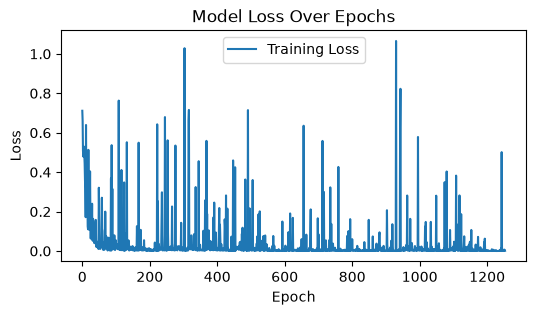

In [45]:
plot_loss_curve(overall_losses)

In [46]:
train_accuracy = get_dataset_accuracy(
    bert_spam_ham_model, tokenized_training_dataset, log_interval=500
)
print(f"Training dataset accuracy: {train_accuracy}")

C:\Users\USER\AppData\Local\Temp\ipykernel_32084\283834730.py:16: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  logits = model(torch.tensor(encoded_message).to(device))


Processed: 0
Processed: 500
Processed: 1000
Processed: 1500
Processed: 2000
Processed: 2500
Processed: 3000
Processed: 3500
Processed: 4000
Processed: 4500
Processed: 5000
4993 / 5016
Accuracy: 99.5414673046252
Training dataset accuracy: 99.5414673046252


In [47]:
validation_accuracy = get_dataset_accuracy(
    bert_spam_ham_model, tokenized_validation_dataset, log_interval=100
)
print(f"Validation dataset accuracy: {validation_accuracy}")

Processed: 0


C:\Users\USER\AppData\Local\Temp\ipykernel_32084\283834730.py:16: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  logits = model(torch.tensor(encoded_message).to(device))


Processed: 100
Processed: 200
Processed: 300
Processed: 400
Processed: 500
555 / 558
Accuracy: 99.46236559139786
Validation dataset accuracy: 99.46236559139786


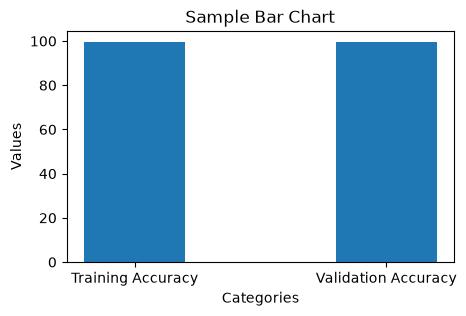

In [48]:
plot_bar_chart(train_accuracy, validation_accuracy)

In [49]:
messages = [
    "Last a chance to win 1 Lakh, call at 5676 now!",
    "How are you doing?",
    "Get home loan at low rates now, click to this link http://win/ to know more",
    "Reaching your location in 5 minutes",
]

for message in messages:
    prediction = bert_spam_ham_model.predict(message)
    print(f"{message} -> {prediction}")

Last a chance to win 1 Lakh, call at 5676 now! -> Spam
How are you doing? -> Not Spam
Get home loan at low rates now, click to this link http://win/ to know more -> Spam
Reaching your location in 5 minutes -> Not Spam
